# Artificial Neural Networks (AIC 380)
**Student Name:** Abdullah Ghaffar  
**Registration No:** FA23-BAI-059  

---
## Lab 05 (Manual Lab 07): Implementation of Learning Vector Quantization (LVQ) in Python

### Objective:
Understanding prototype-based supervised competitive learning with Learning Vector Quantization (LVQ): weight initialization with reference vectors, winner-take-all Euclidean metric, reward/punish weight updates, and classification boundary formation.


### Activity 1: Implementation of LVQs from Scratch


In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

class LVQ:
    # Function computes the winning prototype vector by Euclidean distance
    def winner(self, weights, sample):
        distances = []
        for w in weights:
            dist = sum((s - wi) ** 2 for s, wi in zip(sample, w))
            distances.append(dist)
        return int(np.argmin(distances))

    # Function updates the winning prototype vector
    def update(self, weights, sample, J, alpha, actual):
        # In prototype initialization, prototype 0 represents class 0 and prototype 1 represents class 1
        if actual == J:
            # Reward: move closer to sample
            for i in range(len(sample)):
                weights[J][i] += alpha * (sample[i] - weights[J][i])
        else:
            # Punish: move away from sample
            for i in range(len(sample)):
                weights[J][i] -= alpha * (sample[i] - weights[J][i])

print("LVQ base class defined.")


LVQ base class defined.


### Activity 1 (Driver Code): Synthetic Binary Pattern Training


In [2]:
# Training Samples (m, n) with their class vector
X = [
    [0, 0, 1, 1],
    [1, 0, 0, 0],
    [0, 0, 0, 1],
    [0, 1, 1, 0],
    [1, 1, 0, 0],
    [1, 1, 1, 0]
]
Y = [0, 1, 0, 1, 1, 1]

# Weight initialization: take first sample of class 0 and class 1
weights = []
weights.append(list(X.pop(0)))  # Class 0 prototype
weights.append(list(X.pop(0)))  # Class 1 prototype

# Remaining training samples
Y_train = Y[2:]
X_train = X

ob = LVQ()
epochs = 5
alpha = 0.1

print("Initial Prototypes:\n", np.array(weights))

for epoch in range(epochs):
    for j in range(len(X_train)):
        T = X_train[j]
        winner_idx = ob.winner(weights, T)
        ob.update(weights, T, winner_idx, alpha, Y_train[j])

print("\nTrained Prototype Weights:\n", np.array(weights))

# Classify test pattern
test_sample = [0, 0, 1, 0]
pred_class = ob.winner(weights, test_sample)
print(f"\nTest sample {test_sample} belongs to class: {pred_class}")


Initial Prototypes:
 [[0 0 1 1]
 [1 0 0 0]]

Trained Prototype Weights:
 [[ 0.         -0.145071    0.5694219   1.145071  ]
 [ 0.81690428  0.74581342  0.47926293  0.        ]]

Test sample [0, 0, 1, 0] belongs to class: 1


### Graded Lab Task: LVQ on Benchmark Multiclass Dataset (Iris)


LVQ Test Accuracy on Iris: 84.44%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.72      0.87      0.79        15
   virginica       0.83      0.67      0.74        15

    accuracy                           0.84        45
   macro avg       0.85      0.84      0.84        45
weighted avg       0.85      0.84      0.84        45



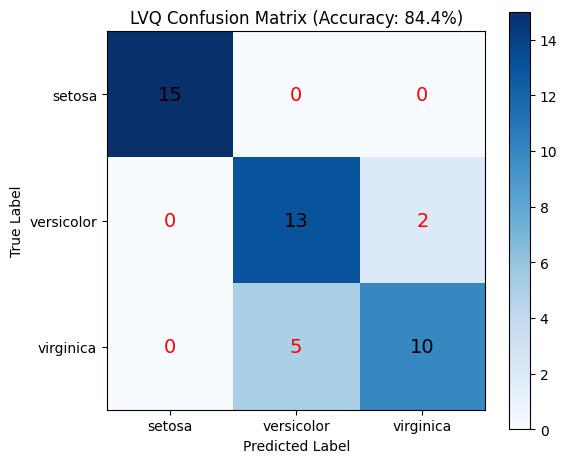

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Load Iris dataset
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

X_tr, X_te, y_tr, y_te = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris)

scaler = StandardScaler()
X_tr_std = scaler.fit_transform(X_tr)
X_te_std = scaler.transform(X_te)

class MultiClassLVQ:
    def __init__(self, n_classes, n_features, alpha=0.1):
        self.n_classes = n_classes
        self.n_features = n_features
        self.alpha = alpha
        self.prototypes = None
        self.proto_labels = None

    def fit(self, X, y, epochs=50):
        # Initialize 1 prototype per class using class centroids
        self.prototypes = np.zeros((self.n_classes, self.n_features))
        self.proto_labels = np.arange(self.n_classes)
        for c in range(self.n_classes):
            self.prototypes[c] = np.mean(X[y == c], axis=0)

        # Training loop with decaying learning rate
        for epoch in range(epochs):
            lr = self.alpha * (1.0 - epoch / epochs)
            for xi, target in zip(X, y):
                # Find winning prototype
                dists = np.linalg.norm(self.prototypes - xi, axis=1)
                winner = np.argmin(dists)
                if self.proto_labels[winner] == target:
                    self.prototypes[winner] += lr * (xi - self.prototypes[winner])
                else:
                    self.prototypes[winner] -= lr * (xi - self.prototypes[winner])

    def predict(self, X):
        preds = []
        for xi in X:
            dists = np.linalg.norm(self.prototypes - xi, axis=1)
            winner = np.argmin(dists)
            preds.append(self.proto_labels[winner])
        return np.array(preds)

lvq_model = MultiClassLVQ(n_classes=3, n_features=4, alpha=0.2)
lvq_model.fit(X_tr_std, y_tr, epochs=40)

y_pred = lvq_model.predict(X_te_std)
acc = accuracy_score(y_te, y_pred)
print(f"LVQ Test Accuracy on Iris: {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_te, y_pred, target_names=iris.target_names))

# Confusion Matrix Visualization
cm = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title(f'LVQ Confusion Matrix (Accuracy: {acc*100:.1f}%)')
plt.colorbar()
ticks = np.arange(3)
plt.xticks(ticks, iris.target_names)
plt.yticks(ticks, iris.target_names)
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='red' if i != j else 'black', fontsize=14)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()
